# First model exploration: a prompted 8B model on the development questions

This notebook scores the first candidate system on the project's task and measures what it costs. The task is the one in the
README: given a person's earlier check-ins, pick the new venue they visit next from five options. The notebook runs on a CPU.
The model itself runs on a GPU cluster through `experiments/score_prompted.py`, which writes the two prediction files this notebook
reads from `results/module7/`. Until those files exist, the cells that need them print a message and skip.

Two runs share the same 2,291 development decisions. Run 1 is the prompted model as it is. Run 2 changes one thing: each option
line also states its distance to the nearest place in the person's history.

## Setup

In [1]:
# Paths, imports and the run files. Every cell that needs a prediction file checks need() first.
import hashlib
import json
import os
import platform
import sys
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "experiments")]
from proxy import arms, datasets, geo, ranking
from proxy.config import CANONICAL
from proxy.paired_stats import bootstrap_delta_ci, paired_user_deltas
import score_prompted

RESULTS = Path(os.environ.get("PROXY_RESULTS", ROOT / "results" / "module7"))
RUN_FILES = {n: (RESULTS / f"{n}_predictions.jsonl", RESULTS / f"{n}_run.json") for n in ("run1", "run2")}
KNOWN_RUN1_TOP1 = 0.3282409428197294      # run 1 on these rows with token-id prompts (see the note in Section 3)
pd.set_option("display.max_colwidth", 80)
print("python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__)


def need(*names):
    """True when the prediction and run files of every named run exist. Otherwise print what is missing."""
    missing = [f"results/module7/{p.name}" for n in names for p in RUN_FILES[n] if not p.exists()]
    if missing:
        print("skipped: waiting for", ", ".join(missing))
    return not missing


def load_run(name):
    preds = [json.loads(line) for line in open(RUN_FILES[name][0])]
    return preds, json.load(open(RUN_FILES[name][1]))

python 3.12.7 | pandas 2.3.1 | numpy 2.5.2


## 1 Role of AI and candidates

The AI system sits between a person's history and a decision. It reads what the person did before and chooses, from five options,
the venue the person would pick. The question is how good that choice can be, and what it costs to get it.

| candidate | what it is | training | hardware |
|---|---|---|---|
| prompted 8B model | an instruction-tuned language model reads the history and the options in a prompt and answers with a letter | none | one GPU, inference only |
| shared LoRA adapter | the same model with a small adapter trained on every person's past choices (`hpc/sft_shared.py`) | supervised, one adapter for all users | one GPU |
| P-DPO | preference-based tuning of the model | training on preference pairs | one GPU |
| FPMC, GRU, SASRec | sequence models over venue ids that do not use a language model (`src/proxy/seqrec.py` has FPMC and a GRU) | trained on the check-in sequences | CPU or one GPU |

**Why the prompted model comes first.** It needs no training, it runs on one GPU, and it sets the baseline every trained candidate
has to beat. A trained system that does not beat it has not earned its training cost. Run 1 is the simplest form of it. Run 2 asks
one question about it: does it use a fact it was not given, the distance from each option to where the person usually goes?

**Parts that use no AI.** Three steps of this notebook are ordinary code on a CPU: the target builder (`proxy.arms.novel_targets`),
the distance computation (`proxy.geo`), and popularity counts (`proxy.ranking.pre_cut_popularity`). They also give three
non-AI baselines on the same rows: random, the most popular option, and the option nearest to the person's history.

**Model and data sources.** Model: `meta-llama/Llama-3.1-8B-Instruct` (Meta), revision `0e9e39f2`, under the Llama 3.1 Community License and Meta's Acceptable Use Policy (gated download). Data: Massive-STEPS New York, revision `1e6af440`, Apache 2.0. Details are in the README.


## Non-AI stages: target builder, distances, popularity

The next cell builds the development questions with the canonical configuration, computes each option's distance to the history
with the haversine formula (great-circle distance on a sphere of radius 6371.0088 km), and counts earlier check-ins per venue.
The release is read from `PROXY_DATA_ROOT` or `data/`. If it is not there, the cell downloads it at the pinned commit and checks its
SHA-256, as `playground.ipynb` does.

In [2]:
# Locate the release, build the 300-user development questions, and compute the distance and popularity features.
NAME = CANONICAL["dataset"]
try:
    datasets.resolve(NAME)
except FileNotFoundError:
    from huggingface_hub import hf_hub_download
    path = hf_hub_download(repo_id="CRUISEResearchGroup/Massive-STEPS-New-York", filename="new_york_checkins.csv",
                           repo_type="dataset", revision="1e6af440a88ee54c83b1e30930290699e194a726")
    assert hashlib.sha256(open(path, "rb").read()).hexdigest() == "edc194f732cb236d841dbee775000c40d9e69bd9668c0aeebf266a159167b3a6"
    datasets.DATASET_PATHS[NAME] = Path(path)

t0 = time.time()
targets, cats = arms.novel_targets(NAME, n_users=CANONICAL["n_users"], seed=CANONICAL["seed"], distractors=CANONICAL["distractors"])
coords = geo.coordinate_table(datasets.load(NAME))
rows = score_prompted.rows_from(targets, cats, coords)
pop = ranking.pre_cut_popularity(NAME)
print(f"built {len(rows):,} decisions of {len({r['user'] for r in rows})} users in {time.time() - t0:.0f} s")
print("venues with coordinates:", f"{len(coords):,}")

built 2,291 decisions of 300 users in 17 s
venues with coordinates: 40,485


The three rules below pick an option without any model. The nearest rule picks the option closest to any place in the history, and
an option with no coordinates counts as farthest. Ties and popularity ties go to the earlier letter. The random rule is seeded.

In [3]:
# The three non-AI baselines on the same rows. `pick` is the chosen option index (0 is A).
def with_picks(picks):
    return [{"user": r["user"], "answer_idx": r["answer_idx"], "pick": p} for r, p in zip(rows, picks)]

non_ai = {
    "random (seed 0)": with_picks(ranking.random_picks(len(rows), seed=0)),
    "most popular option": with_picks([ranking.popularity_pick([pop.get(c, 0) for c in t.candidates]) for t in targets]),
    "nearest to the history": with_picks([ranking.nearest_rule_pick(r["cand_km"]) for r in rows]),
}
table = []
for k_, v in non_ai.items():
    acc, lo, hi = ranking.pooled_accuracy_ci(v)
    table.append({"rule": k_, "top-1": round(acc, 4), "95% CI": f"{lo:.3f} to {hi:.3f}", "n": len(v)})
display(pd.DataFrame(table))
print("chance with five options: 0.200")

,rule,top-1,95% CI,n
0,random (seed 0),0.2100,0.193 to 0.227,2291
1,most popular option,0.2117,0.195 to 0.229,2291
2,nearest to the history,0.4548,0.426 to 0.483,2291


chance with five options: 0.200


### Tests of the distance function

The boundary cases are also in `tests/test_module7.py`. Here they run on their own: the same point, antipodal points, a pair a degree
apart, the date line, and a missing coordinate.

In [4]:
half_circle = np.pi * geo.EARTH_R_KM
checks = [
    ("same point", geo.haversine_km(40.7, -74.0, 40.7, -74.0), 0.0),
    ("antipodes (pole to pole)", geo.haversine_km(90.0, 0.0, -90.0, 0.0), half_circle),
    ("antipodes (equator, 180 degrees)", geo.haversine_km(0.0, 0.0, 0.0, 180.0), half_circle),
    ("one degree of latitude", geo.haversine_km(0.0, 0.0, 1.0, 0.0), np.radians(1) * geo.EARTH_R_KM),
    ("across the date line", geo.haversine_km(0.0, 179.5, 0.0, -179.5), np.radians(1) * geo.EARTH_R_KM),
]
out = pd.DataFrame([{"case": c, "computed km": round(v, 4), "expected km": round(e, 4), "ok": abs(v - e) < 1e-3} for c, v, e in checks])
missing = geo.haversine_km(None, -74.0, 40.7, -74.0)
display(pd.concat([out, pd.DataFrame([{"case": "missing latitude", "computed km": "none", "expected km": "none", "ok": missing is None}])],
                  ignore_index=True))
assert out["ok"].all() and missing is None

,case,computed km,expected km,ok
0,same point,0.0,0.0,True
1,antipodes (pole to pole),20015.1144,20015.1144,True
2,"antipodes (equator, 180 degrees)",20015.1144,20015.1144,True
3,one degree of latitude,111.1951,111.1951,True
4,across the date line,111.1951,111.1951,True
5,missing latitude,none,none,True


## 2 Data

In [5]:
# Shapes: decisions, users, rows per user, options per question.
df = pd.DataFrame({"user": [r["user"] for r in rows], "answer_idx": [r["answer_idx"] for r in rows],
                   "k": [r["k"] for r in rows], "n_hist": [len(t.history) for t in targets]})
per_user = df.groupby("user").size()
print(f"{len(df):,} decisions | {df.user.nunique()} users | options per question: {dict(Counter(df.k))}")
display(per_user.describe(percentiles=[0.1, 0.5, 0.9]).round(1).to_frame("decisions per user"))
print("earlier check-ins per user (all of them, 30 are shown in the prompt):")
display(df.groupby("user").n_hist.max().describe(percentiles=[0.1, 0.5, 0.9]).round(1).to_frame("history length"))

2,291 decisions | 300 users | options per question: {5: 2291}


,decisions per user
count,300.0
mean,7.6
std,5.6
min,1.0
10%,3.9
50%,6.0
90%,14.0
max,41.0


earlier check-ins per user (all of them, 30 are shown in the prompt):


,history length
count,300.0
mean,48.9
std,56.2
min,16.0
10%,17.0
50%,31.0
90%,99.3
max,521.0


In [6]:
# Where the right answer sits. A fair draw puts it at each letter 20% of the time.
pos = df.answer_idx.map(lambda i: "ABCDE"[i]).value_counts().sort_index()
exp = len(df) / 5
display(pd.DataFrame({"count": pos, "share": (pos / len(df)).round(3), "expected": exp, "z": ((pos - exp) / np.sqrt(len(df) * 0.2 * 0.8)).round(2)}))
print("a prompted model that always answers the most common letter would score", round(pos.max() / len(df), 3))

,count,share,expected,z
answer_idx,,,,
A,487,0.213,458.2,1.50
B,409,0.179,458.2,-2.57
C,447,0.195,458.2,-0.58
D,457,0.199,458.2,-0.06
E,491,0.214,458.2,1.71


a prompted model that always answers the most common letter would score 0.214


**Missing coordinates.** Private places such as homes carry no name or coordinates in the release, and the same holds for a few
venues. An option without coordinates has no distance. The cell below counts them. They are not dropped and not guessed. Run 2
prints "distance unknown" on such an option line, and the nearest rule ranks such an option last.

In [7]:
# Missing coordinates among the options, the answers and the histories.
km = np.array([[np.nan if x is None else x for x in r["cand_km"]] for r in rows])
ans_km = np.array([km[i, r["answer_idx"]] for i, r in enumerate(rows)])
hist_located = np.array([np.mean([coords.get(h) is not None for h in t.history]) for t in targets])
print(f"option slots with no distance: {np.isnan(km).mean():.1%} of {km.size:,}")
print(f"answer with no distance: {np.isnan(ans_km).mean():.1%} of decisions")
print(f"decisions with no option at all located: {int(np.isnan(km).all(axis=1).sum())}")
print(f"histories: median share of located places {np.median(hist_located):.0%}, histories with none located {int((hist_located == 0).sum())}")
print("median distance to the nearest history place, km: answer", round(float(np.nanmedian(ans_km)), 2),
      "| wrong options", round(float(np.nanmedian(np.where(np.arange(5) == np.array([r["answer_idx"] for r in rows])[:, None], np.nan, km))), 2))

option slots with no distance: 8.6% of 11,455
answer with no distance: 4.3% of decisions
decisions with no option at all located: 1
histories: median share of located places 96%, histories with none located 0
median distance to the nearest history place, km: answer 0.38 | wrong options 1.15


In [8]:
# Split check. The 300 held-out test users are drawn with another seed, after the development users are removed from the pool.
# Only the user ids of that draw are compared here. No test question, prompt or prediction is read.
dev_users = {r["user"] for r in rows}
test_draw, _ = arms.novel_targets(NAME, n_users=300, seed=ranking.TEST_SEED, exclude_users=dev_users)
test_users = {t.user for t in test_draw}
print(f"development users {len(dev_users)} | test users {len(test_users)} | users in both: {len(dev_users & test_users)}")
assert not dev_users & test_users

development users 300 | test users 300 | users in both: 0


**Leakage check.** The prompt shows only check-ins made before the decision. The right answer is a venue the person has not
visited before, and the four wrong options are never drawn from the person's history. The wrong options are matched on popularity
counted from check-ins before each user's split, so popularity does not point to the answer. The distance added in run 2 uses only the
history and the option coordinates, both known at the time of the decision. The answer is nearer than the wrong options (median 0.38 km
against 1.15 km above), which is why the cue can help, and why the nearest rule is the bar it has to clear. Nothing is fitted in this
notebook, and the test users stay unused.

## 3 Run 1: configuration

**A scoring fix.** The first version of the scoring script passed the chat template to vLLM as text. The template already starts with the begin-of-text token, and vLLM tokenized the text again and added a second one. The script now passes token ids built without special tokens, so each prompt carries exactly one begin-of-text token, and it stops if any prompt does not. Run 1 moved from 0.3274 to 0.3282 and run 2 from 0.3898 to 0.3885. The numbers below use the corrected script.


In [9]:
# The configuration of run 1 as the run file recorded it.
if need("run1"):
    preds1, run1 = load_run("run1")
    cfg = run1["config"]
    items = [("model", cfg["model"]), ("revision", cfg["revision_used"]), ("dataset", cfg["dataset"]), ("split", cfg["split"]),
             ("decoy condition", cfg["distractors"]), ("users, decisions", f"{cfg['n_users']}, {cfg['n_rows']:,}"),
             ("seed, history shown", f"{cfg['seed']}, {cfg['hist_n']} most recent"), ("prompt", cfg["prompt"]),
             ("training", "none (zero-shot)"), ("decoding", f"greedy, answer constrained to {list('ABCDE')}"),
             ("batch invariant", cfg["decoding"]["VLLM_BATCH_INVARIANT"]), ("versions", cfg["versions"])]
    display(pd.DataFrame(items, columns=["setting", "value"]).astype(str))

,setting,value
0,model,meta-llama/Llama-3.1-8B-Instruct
1,revision,0e9e39f249a16976918f6564b8830bc894c89659
2,dataset,steps_new_york
3,split,development
4,decoy condition,popmatched
5,"users, decisions","300, 2,291"
6,"seed, history shown","0, 30 most recent"
7,prompt,canonical
8,training,none (zero-shot)
9,decoding,"greedy, answer constrained to ['A', 'B', 'C', 'D', 'E']"


## 4 Evaluation of run 1

In [10]:
# Row alignment and the check against the expected value from the first run. The predictions must belong to the rows built above.
def aligned(preds, name):
    assert len(preds) == len(rows), (name, len(preds), len(rows))
    assert all(p["user"] == r["user"] and p["answer_idx"] == r["answer_idx"] for p, r in zip(preds, rows)), f"{name}: rows differ"

if need("run1"):
    aligned(preds1, "run1")
    md5 = score_prompted.md5("\n".join(r["prompt"] for r in rows))
    print("prompts equal the ones scored:", md5 == cfg["prompt_md5"])
    acc1, lo1, hi1 = ranking.pooled_accuracy_ci(preds1)
    print(f"top-1 {acc1:.4f} (95% CI {lo1:.3f} to {hi1:.3f}, resampling users) | expected {KNOWN_RUN1_TOP1:.4f} | "
          f"{'MATCH' if abs(acc1 - KNOWN_RUN1_TOP1) < 1e-12 else 'DIFFERENT'}")

prompts equal the ones scored: True
top-1 0.3282 (95% CI 0.305 to 0.351, resampling users) | expected 0.3282 | MATCH


In [11]:
# Top-1, Acc@2 and MRR. The last two come from the five letter log-probabilities (ties are not counted against the answer).
if need("run1"):
    print("unparsed answers:", sum(p["pick"] is None for p in preds1))
    print("decoded pick differs from the largest log-prob on", run1["result"]["pick_differs_from_max_logprob"], "rows")
    display(pd.DataFrame([{"metric": "top-1", "value": round(acc1, 4), "95% CI": f"{lo1:.3f} to {hi1:.3f}", "chance": 0.20},
                          {"metric": "Acc@2", "value": round(ranking.acc_at(preds1, 2), 4), "95% CI": "", "chance": 0.40},
                          {"metric": "MRR", "value": round(ranking.mrr(preds1), 4), "95% CI": "", "chance": round(sum(1 / r for r in range(1, 6)) / 5, 4)}]))
    print("the same top-1 averaged over users instead of decisions:", round(float(np.mean(list(ranking.per_user_accuracy(preds1).values()))), 4))

unparsed answers: 0
decoded pick differs from the largest log-prob on 0 rows


,metric,value,95% CI,chance
0,top-1,0.3282,0.305 to 0.351,0.2000
1,Acc@2,0.5858,,0.4000
2,MRR,0.5754,,0.4567


the same top-1 averaged over users instead of decisions: 0.3241


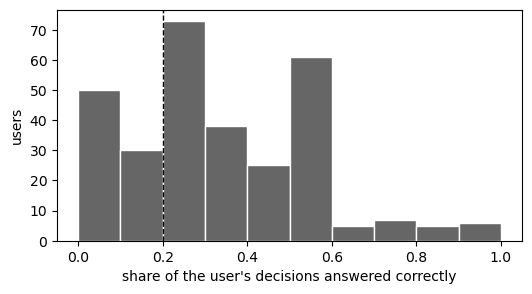

users with accuracy 0: 48 | above chance (0.2): 201 of 300


In [12]:
# Accuracy of each user. With about 8 decisions per user the spread is wide even for a model that treats everyone alike.
if need("run1"):
    pu1 = np.array(list(ranking.per_user_accuracy(preds1).values()))
    try:
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(6, 3))
        ax.hist(pu1, bins=np.linspace(0, 1, 11), color="0.4", edgecolor="white")
        ax.axvline(0.2, color="k", ls="--", lw=1)
        ax.set_xlabel("share of the user's decisions answered correctly")
        ax.set_ylabel("users")
        plt.show()
    except ImportError:
        counts, edges = np.histogram(pu1, bins=np.linspace(0, 1, 11))
        display(pd.DataFrame({"accuracy from": edges[:-1].round(1), "users": counts}))
    print("users with accuracy 0:", int((pu1 == 0).sum()), "| above chance (0.2):", int((pu1 > 0.2).sum()), "of", len(pu1))

## 5 Ten inspected errors of run 1

The rule is fixed in advance: among the wrong answers, take the ten with the highest confidence, where confidence is the probability
the model gives its own pick (softmax of the five letter log-probabilities). A person appears at most once, so no case shows two
check-ins of the same person. A case shows the history as a summary only, then the five options with their distances, the model's pick
and the truth.

In [13]:
# The ten most confident wrong answers, one per user, in order of confidence.
def conf_wrong(preds):
    out = []
    for i, p in enumerate(preds):
        if p["pick"] is not None and p["pick"] != p["answer_idx"]:
            out.append((float(ranking.probs(p["logprobs"])[p["pick"]]), i))
    return sorted(out, key=lambda x: (-x[0], x[1]))

def ten_errors(preds):
    seen, chosen = set(), []
    for c, i in conf_wrong(preds):
        if preds[i]["user"] not in seen:
            seen.add(preds[i]["user"])
            chosen.append((c, i))
        if len(chosen) == 10:
            break
    return chosen

def show_case(n, conf, i, preds):
    t, r, p = targets[i], rows[i], preds[i]
    hist_cats = Counter(arms._cat(cats, h) for h in t.history)
    located = np.mean([coords.get(h) is not None for h in t.history])
    top = ", ".join(c for c, _ in hist_cats.most_common(3))
    print(f"Case {n} | confidence {conf:.2f} | pick {'ABCDE'[p['pick']]} | truth {'ABCDE'[p['answer_idx']]}")
    print(f"  history: {len(t.history)} earlier places, {located:.0%} located, most frequent categories: {top}")
    for j, c in enumerate(t.candidates):
        mark = "PICK " if j == p["pick"] else ("TRUTH" if j == p["answer_idx"] else "     ")
        d = r["cand_km"][j]
        print(f"  {mark} {'ABCDE'[j]}. {arms._label(cats, c)} | {'no distance' if d is None else f'{d:.1f} km'} | p = {ranking.probs(p['logprobs'])[j]:.2f}")
    print()

if need("run1"):
    errs = ten_errors(preds1)
    for n, (c, i) in enumerate(errs, 1):
        show_case(n, c, i, preds1)

Case 1 | confidence 1.00 | pick E | truth D
  history: 23 earlier places, 100% located, most frequent categories: Building, Neighborhood, Park
        A. Park Avenue Armory (Event Space) | 1.0 km | p = 0.00
        B. Starbucks (Coffee Shop) | 0.6 km | p = 0.00
        C. Dunkin' (Coffee Shop) | 3.2 km | p = 0.00
  TRUTH D. SoHo Park (Burger Joint) | 1.7 km | p = 0.00
  PICK  E. Madison Square Park (Park) | 0.7 km | p = 1.00

Case 2 | confidence 0.99 | pick C | truth D
  history: 52 earlier places, 96% located, most frequent categories: Coffee Shop, Theater, Thrift / Vintage Store
        A. Target (Big Box Store) | 8.6 km | p = 0.00
        B. Silver Lake Park Dog Run (Dog Run) | 12.0 km | p = 0.00
  PICK  C. Tompkins Square Park (Park) | 0.4 km | p = 0.99
  TRUTH D. Gershwin Theatre (Theater) | 0.2 km | p = 0.00
        E. The Golden Krust Palace (Track Stadium) | 0.4 km | p = 0.00

Case 3 | confidence 0.99 | pick E | truth D
  history: 72 earlier places, 99% located, most frequent c

In [14]:
# What the ten have in common, counted from the cases above.
def case_facts(i, p):
    t, r = targets[i], rows[i]
    j, a = p["pick"], p["answer_idx"]
    hist_top = {c for c, _ in Counter(arms._cat(cats, h) for h in t.history).most_common(6)}
    d = [np.nan if x is None else x for x in r["cand_km"]]
    return {"pick has no distance": np.isnan(d[j]), "truth has no distance": np.isnan(d[a]),
            "pick is nearer than truth": bool(d[j] < d[a]) if not (np.isnan(d[j]) or np.isnan(d[a])) else False,
            "pick is the nearest option": bool(np.nanargmin(d) == j) if not np.isnan(d).all() else False,
            "pick category is in the history's top 6": arms._cat(cats, t.candidates[j]) in hist_top,
            "truth category is in the history's top 6": arms._cat(cats, t.candidates[a]) in hist_top,
            "pick is the most popular option": int(np.argmax([pop.get(c, 0) for c in t.candidates])) == j}

if need("run1"):
    facts = pd.DataFrame([case_facts(i, preds1[i]) for _, i in errs])
    allw = pd.DataFrame([case_facts(i, p) for i, p in enumerate(preds1) if p["pick"] != p["answer_idx"]])
    display(pd.DataFrame({"of the ten": facts.sum().astype(int), "of all wrong answers": (allw.mean() * 100).round(0).astype(int).astype(str) + "%"}))

,of the ten,of all wrong answers
pick has no distance,0,11%
truth has no distance,1,4%
pick is nearer than truth,5,27%
pick is the nearest option,1,16%
pick category is in the history's top 6,7,27%
truth category is in the history's top 6,2,9%
pick is the most popular option,4,15%


**What the ten have in common.** In 7 of the 10, the model picked a place from a category the person visits often, while the real choice came from one of the person's six most frequent categories only twice. Distance does not separate them here: the pick was nearer than the real choice in 5 of the 9 cases where both distances are known. Every one of the ten was picked with confidence 0.98 or higher. The model leans on the person's usual categories and is confidently wrong when the person tries something new. Run 2 tests whether stating the distances helps, since the nearest-place rule alone scores 0.455 on these rows.


### Constraints of run 1 against the project's targets

In [15]:
# Measured constraints from the run file. The right-hand column holds the project's targets from Section 2.1.
def constraint_table(names):
    runs = {n: load_run(n)[1]["constraints"] for n in names}
    keys = [("model_load_seconds", "model load, seconds"), ("scoring_seconds", "scoring, seconds"),
            ("decisions_per_second", "decisions per second"), ("mean_latency_ms_per_decision", "mean latency per decision, ms"),
            ("peak_gpu_memory_gb_torch_allocated", "peak GPU memory, GB (torch allocated)"),
            ("peak_gpu_memory_gb_driver", "peak GPU memory, GB (driver)"), ("kv_cache_gb", "KV cache, GB"), ("gpu_hours", "GPU hours")]
    target = {"model_load_seconds": "within the 15-minute pass", "scoring_seconds": "within the 15-minute pass",
              "gpu_hours": "at most 0.25 (15 minutes)"}
    t = pd.DataFrame([{"constraint": lab, **{n: runs[n].get(k) for n in names}, "project target": target.get(k, "")} for k, lab in keys])
    met = ["met" if runs[n]["gpu_hours"] * 60 <= 15 else "not met" for n in names]
    t.loc[len(t)] = ["Section 2.1 (R5): one scoring pass over about 2,300 decisions in at most 15 minutes on one GPU, model load included",
                     *met, "15 minutes"]
    return t

if need("run1"):
    display(constraint_table(["run1"]))
    print("latency is scoring time divided by decisions with 512 prompts per batch, so it is a throughput figure and not the delay of one request")

,constraint,run1,project target
0,"model load, seconds",57.2,within the 15-minute pass
1,"scoring, seconds",9.2,within the 15-minute pass
2,decisions per second,248.95,
3,"mean latency per decision, ms",4.02,
4,"peak GPU memory, GB (torch allocated)",0.0,
5,"peak GPU memory, GB (driver)",166.12,
6,"KV cache, GB",143.95,
7,GPU hours,0.0224,at most 0.25 (15 minutes)
8,"Section 2.1 (R5): one scoring pass over about 2,300 decisions in at most 15 ...",met,15 minutes


latency is scoring time divided by decisions with 512 prompts per batch, so it is a throughput figure and not the delay of one request


## 6 Run 2: the same rows with the distance on each option

One change: each option line ends with the distance to the nearest place in the person's history, for example `[2.3 km from the nearest
place in their history]`, or `[distance unknown]` when the option has no coordinates. The model, the decoding, the history shown and
the rows are the same. The paired difference is computed per user, as in `src/proxy/paired_stats.py`.

In [16]:
# Run 2 on the same rows, and the paired difference to run 1.
if need("run1", "run2"):
    preds2, run2 = load_run("run2")
    aligned(preds2, "run2")
    cued = [geo.add_cue(r["prompt"], r["cand_km"]) for r in rows]
    print("prompts equal the ones scored:", score_prompted.md5("\n".join(cued)) == run2["config"]["prompt_md5"])
    acc2, lo2, hi2 = ranking.pooled_accuracy_ci(preds2)
    deltas, _ = paired_user_deltas(preds2, preds1)
    dlo, dhi = bootstrap_delta_ci(deltas)
    print(f"run 2 top-1 {acc2:.4f} (95% CI {lo2:.3f} to {hi2:.3f}) | run 1 {acc1:.4f}")
    print(f"paired difference, run 2 minus run 1, averaged over users: {deltas.mean():+.4f} (95% CI {dlo:+.3f} to {dhi:+.3f}), "
          f"pooled over decisions {acc2 - acc1:+.4f}")
    print(f"Acc@2 {ranking.acc_at(preds2, 2):.4f} | MRR {ranking.mrr(preds2):.4f} (run 1: {ranking.acc_at(preds1, 2):.4f}, {ranking.mrr(preds1):.4f})")

prompts equal the ones scored: True
run 2 top-1 0.3885 (95% CI 0.365 to 0.412) | run 1 0.3282
paired difference, run 2 minus run 1, averaged over users: +0.0715 (95% CI +0.045 to +0.099), pooled over decisions +0.0602
Acc@2 0.6268 | MRR 0.6158 (run 1: 0.5858, 0.5754)


In [17]:
# Flips: which decisions changed from right to wrong or from wrong to right, and where the new pick came from.
if need("run1", "run2"):
    ok1 = np.array([p["pick"] == p["answer_idx"] for p in preds1])
    ok2 = np.array([p["pick"] == p["answer_idx"] for p in preds2])
    flips = pd.DataFrame({"run 2 right": [int((ok1 & ok2).sum()), int((~ok1 & ok2).sum())],
                          "run 2 wrong": [int((ok1 & ~ok2).sum()), int((~ok1 & ~ok2).sum())]}, index=["run 1 right", "run 1 wrong"])
    display(flips)
    b, c = int((ok1 & ~ok2).sum()), int((~ok1 & ok2).sum())
    print(f"right only in run 1: {b} | right only in run 2: {c} | exact sign test p = {ranking.sign_test_p(b, c):.3f}")
    nearest = np.array([ranking.nearest_rule_pick(r["cand_km"]) for r in rows])
    pick1, pick2 = np.array([p["pick"] for p in preds1]), np.array([p["pick"] for p in preds2])
    print(f"decisions where the pick changed: {int((pick1 != pick2).sum())} of {len(rows)}")
    display(pd.DataFrame({"share of picks that are the nearest option": [round(float((pick1 == nearest).mean()), 3), round(float((pick2 == nearest).mean()), 3)],
                          "share of picks at the letter A": [round(float((pick1 == 0).mean()), 3), round(float((pick2 == 0).mean()), 3)]},
                         index=["run 1", "run 2"]))

,run 2 right,run 2 wrong
run 1 right,499,253
run 1 wrong,391,1148


right only in run 1: 253 | right only in run 2: 391 | exact sign test p = 0.000
decisions where the pick changed: 1141 of 2291


,share of picks that are the nearest option,share of picks at the letter A
run 1,0.261,0.118
run 2,0.490,0.035


In [18]:
# Verdict. The rule is fixed: the cue helped if the interval of the paired difference lies above zero, hurt if it lies below.
if need("run1", "run2"):
    nearest_acc = ranking.pooled_accuracy_ci(non_ai["nearest to the history"])[0]
    if dlo > 0:
        verdict = "The distance cue raised top-1 accuracy"
    elif dhi < 0:
        verdict = "The distance cue lowered top-1 accuracy"
    else:
        verdict = "The distance cue did not change top-1 accuracy by a detectable amount"
    print(f"{verdict}: {deltas.mean():+.3f} (95% CI {dlo:+.3f} to {dhi:+.3f}), run 2 at {acc2:.3f} against {nearest_acc:.3f} for the nearest rule alone.")

The distance cue raised top-1 accuracy: +0.071 (95% CI +0.045 to +0.099), run 2 at 0.388 against 0.455 for the nearest rule alone.


### Experiment table

In [19]:
# One row per run: configuration, the change, the metric with its interval, n, runtime and GPU hours.
def table_row(label, config, change, preds, constraints=None):
    acc, lo, hi = ranking.pooled_accuracy_ci(preds)
    return {"run": label, "configuration": config, "change": change, "top-1 (95% CI)": f"{acc:.3f} ({lo:.3f} to {hi:.3f})",
            "n": len(preds), "runtime": "CPU, seconds" if constraints is None else f"{constraints['scoring_seconds']:.0f} s scoring, {constraints['model_load_seconds']:.0f} s load",
            "GPU hours": 0 if constraints is None else constraints["gpu_hours"]}

exp = [table_row("random", "seeded random option", "none", non_ai["random (seed 0)"]),
       table_row("popularity", "most popular option", "none", non_ai["most popular option"]),
       table_row("nearest rule", "option nearest to any history place", "none", non_ai["nearest to the history"])]
if need("run1"):
    exp.append(table_row("run 1", "prompted Llama-3.1-8B-Instruct, zero-shot, constrained letter", "first candidate", preds1, run1["constraints"]))
if need("run1", "run2"):
    exp.append(table_row("run 2", "run 1 plus distance to the nearest history place on each option", "one change", preds2, run2["constraints"]))
display(pd.DataFrame(exp))

,run,configuration,change,top-1 (95% CI),n,runtime,GPU hours
0,random,seeded random option,none,0.210 (0.193 to 0.227),2291,"CPU, seconds",0.0000
1,popularity,most popular option,none,0.212 (0.195 to 0.229),2291,"CPU, seconds",0.0000
2,nearest rule,option nearest to any history place,none,0.455 (0.426 to 0.483),2291,"CPU, seconds",0.0000
3,run 1,"prompted Llama-3.1-8B-Instruct, zero-shot, constrained letter",first candidate,0.328 (0.305 to 0.351),2291,"9 s scoring, 57 s load",0.0224
4,run 2,run 1 plus distance to the nearest history place on each option,one change,0.388 (0.365 to 0.412),2291,"13 s scoring, 60 s load",0.0241


## Next steps

- Train the shared LoRA adapter on everyone's past choices and score it on these same rows, with the same two prompts.
- If a model with the distance cue and the nearest rule disagree often, test a combination of the two and report it against both.
- Score the 300 test users once, at the end, with the settings chosen on the development users.